# 02 · FLUX 3 Image Klein on MPS — FP8 with torch 2.15

torch 2.15 is the first release whose MPS backend has `torch.float8_e4m3fn` and an `F.scaled_mm` kernel; on 2.14, `x.to(torch.float8_e4m3fn)` on MPS fails with *Undefined type Float8_e4m3fn*.

Kernel: **FLUX3 (torch 2.15)** (`.venv-torch215`, `make kernels`). Run notebook 01 first: this one reuses its `outputs/caption.txt`.

The FP8 transformer uses BFL's **fp8r** layout (E4M3 weights + fp32 per-row scale), loaded by diffusers' `BFLQuantizationConfig` into `BFLFP8RLinear` layers. There are three ways to run its matmuls on MPS (`mps_flux_3_fp8.fp8.set_fp8r_backend`):

| backend | what runs | notes |
|---|---|---|
| `diffusers` | stock: dequant fp8→fp32→bf16 each call, bf16 GEMM | weight-only FP8 |
| `dequant` | fp8→bf16 cast, per-row scale on the smaller of weight/output, bf16 GEMM | weight-only FP8, fastest |
| `scaled_mm` | activations quantized per row, `F.scaled_mm(RowWise)` | true FP8 compute; slow on MPS today |

Synthetic per-step benchmark (`scripts/bench_transformer.py`, M5 Max, 1024², 512 text tokens): bf16 1.09 s · fp8r/diffusers 1.38 s · fp8r/dequant 1.32 s · fp8r/scaled_mm 6.11 s. Transformer weights drop 10.3 → 5.4 GiB.

In [1]:
import json
import os
from pathlib import Path

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "0")

import diffusers
import torch
import transformers
from IPython.display import display

from mps_flux_3_fp8.flux3 import (
    REPO_DISTILLED,
    free_mps,
    generate,
    load_pipeline,
    module_gib,
    psnr,
    save,
)
from mps_flux_3_fp8.fp8 import probe_mps_fp8

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
RESULTS = OUT / "results.json"


def record(name: str, seconds: float, transformer_gib: float, **extra) -> dict:
    """Append one run to outputs/results.json so the notebooks can compare across torch versions."""
    results = json.loads(RESULTS.read_text()) if RESULTS.exists() else {}
    results[name] = {
        "torch": torch.__version__,
        "seconds": round(seconds, 2),
        "transformer_gib": round(transformer_gib, 2),
        **extra,
    }
    RESULTS.write_text(json.dumps(results, indent=2))
    return results[name]


print(f"torch {torch.__version__} | diffusers {diffusers.__version__} | transformers {transformers.__version__}")
print("MPS available:", torch.backends.mps.is_available())
print(probe_mps_fp8())

from diffusers import BFLQuantizationConfig, Flux3Transformer2DModel

from mps_flux_3_fp8.fp8 import quantize_linears_fp8r, set_fp8r_backend

assert probe_mps_fp8().float8_e4m3fn, "this notebook needs torch >= 2.15 (MPS float8_e4m3fn)"

/Users/njindal/build/mps_flux_3_fp8/.venv-torch215/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 16:08:58.202000 97949 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


torch 2.15.0 | diffusers 0.43.0 | transformers 5.23.0
MPS available: True
MpsFp8Support(torch_version='2.15.0', mps_available=True, float8_e4m3fn=True, scaled_mm=True, error=None)


In [2]:
REQUEST = "A man walking with his dog along a neighborhood sidewalk, afternoon sun"
SEED = 0
HEIGHT = WIDTH = 1024

# "checkpoint": BFL's official variants/fp8r/model.safetensors (6.3 GB download)
# "quantize":   quantize the bf16 transformer in place with the same fp8r scheme (no download)
FP8_SOURCE = "checkpoint"
BACKENDS = ["diffusers", "dequant", "scaled_mm"]  # scaled_mm adds ~1.5 min per image

caption_path = OUT / "caption.txt"
assert caption_path.exists(), "run notebook 01 first (it writes outputs/caption.txt)"
caption = caption_path.read_text()
print(caption)

Full-color outdoor photograph taken at eye level in warm afternoon sunlight, showing a man walking his dog along a neighborhood sidewalk. In the foreground, a white man in his thirties with fair skin, short brown hair, and light stubble walks from left to right near the center. He wears a faded navy T-shirt, tan chinos, and worn grey walking shoes, with a canvas key ring hanging from his belt. His left foot is lifted mid-step and his right hand holds a loose brown leather leash. Beside him, a medium-sized golden retriever walks with its head lowered toward the pavement, its golden coat catching the sunlight and its tail hanging behind it. The leash curves between the man’s hand and the dog’s red collar. Long shadows from both figures stretch diagonally across the concrete sidewalk toward the lower left. A narrow strip of grass borders the path, with dry leaves and a flattened paper cup near the curb. On the right, modest detached houses stand behind short front lawns and low hedges. On

## 1 · bf16 baseline on torch 2.15 (same caption, same seed)

/Users/njindal/build/mps_flux_3_fp8/.venv-torch215/lib/python3.13/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 713/713 [00:00<00:00, 25716.88it/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 757.37it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

... (7 outputs left out)

 94%|█████████▍| 15/16 [00:00<00:00, 141.54it/s]

100%|██████████| 16/16 [00:00<00:00, 141.36it/s]

2026-11-17 16:09:24,428 - mps_flux_3_fp8 - /Users/njindal/build/mps_flux_3_fp8/src/mps_flux_3_fp8/flux3.py:147 - INFO - Generated 1024x1024 in 17.9s (allocated=18.98 GiB, driver=30.22 GiB)


{'torch': '2.15.0', 'seconds': 17.85, 'transformer_gib': 10.34, 'memory': 'allocated=18.98 GiB, driver=30.22 GiB'}


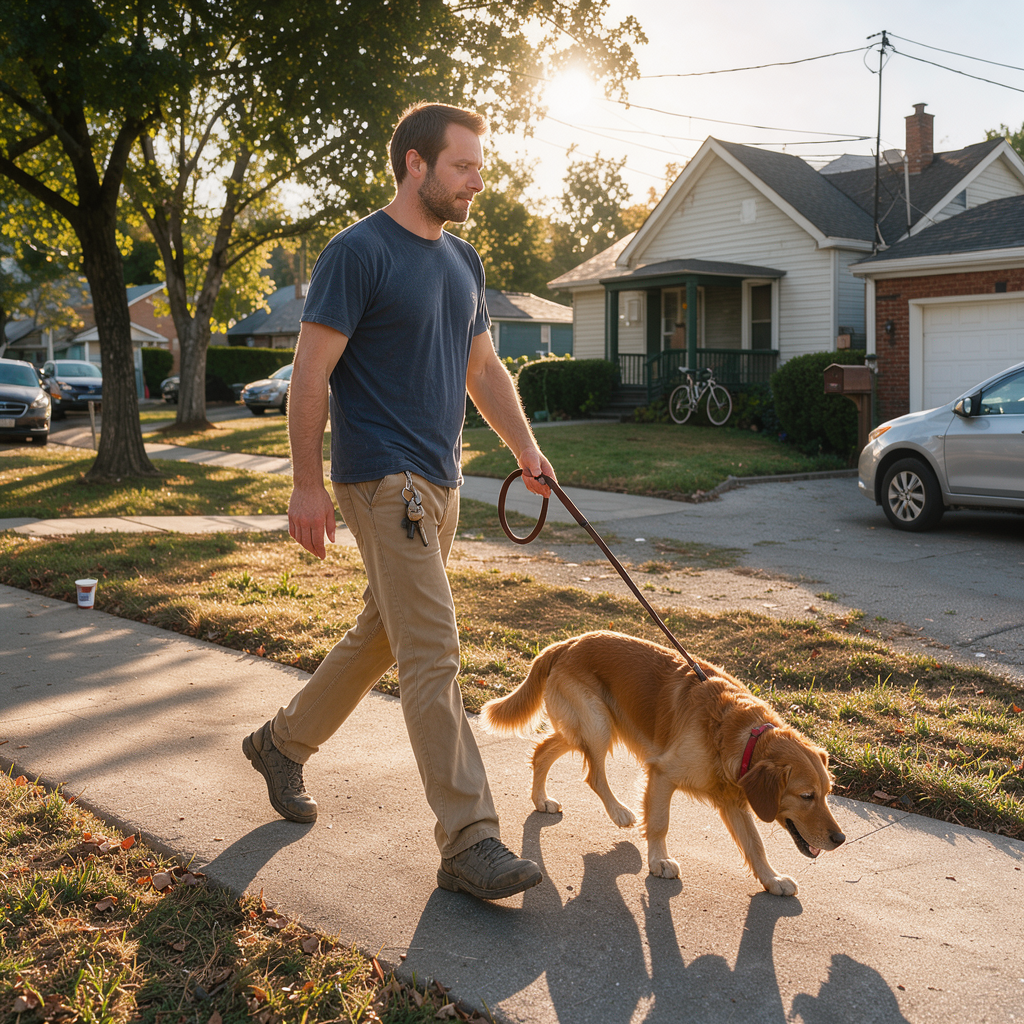

In [3]:
pipe = load_pipeline(REPO_DISTILLED, with_upsampler=False)
_ = generate(pipe, caption, seed=SEED, height=512, width=512, num_inference_steps=2)  # warm-up
bf16 = generate(pipe, caption, seed=SEED, height=HEIGHT, width=WIDTH)
save(bf16.image, OUT / "bf16_torch215.png")
print(record("bf16_torch215", bf16.seconds, module_gib(pipe.transformer), memory=str(bf16.memory)))
display(bf16.image)

## 2 · Swap in the FP8 (fp8r) transformer

In [4]:
match FP8_SOURCE:
    case "checkpoint":
        transformer = Flux3Transformer2DModel.from_single_file(
            f"https://huggingface.co/{REPO_DISTILLED}/blob/main/variants/fp8r/model.safetensors",
            config=REPO_DISTILLED,
            subfolder="transformer",
            quantization_config=BFLQuantizationConfig(compute_dtype=torch.bfloat16),
            dtype=torch.bfloat16,
        ).to("mps")
        pipe.update_components(transformer=transformer)
        del transformer
    case "quantize":
        quantize_linears_fp8r(pipe.transformer)
    case _:
        raise ValueError(FP8_SOURCE)

print("after swap:", free_mps())
fp8_gib = module_gib(pipe.transformer)
print(f"transformer: {fp8_gib:.2f} GiB, weight dtypes:", sorted({str(p.dtype) for p in pipe.transformer.parameters()}))

after swap: allocated=14.48 GiB, driver=21.69 GiB
transformer: 5.84 GiB, weight dtypes: ['torch.bfloat16', 'torch.float32', 'torch.float8_e4m3fn']


## 3 · Generate with each FP8 backend

In [5]:
fp8_runs = {}
for backend in BACKENDS:
    set_fp8r_backend(pipe.transformer, backend)
    _ = generate(pipe, caption, seed=SEED, height=512, width=512, num_inference_steps=2)  # warm-up
    run = generate(pipe, caption, seed=SEED, height=HEIGHT, width=WIDTH)
    fp8_runs[backend] = run
    save(run.image, OUT / f"fp8r_{backend}_torch215.png")
    print(
        record(
            f"fp8r_{backend}_torch215",
            run.seconds,
            fp8_gib,
            source=FP8_SOURCE,
            psnr_vs_bf16=round(psnr(bf16.image, run.image), 2),
            memory=str(run.memory),
        )
    )

2026-11-17 16:24:38,640 - mps_flux_3_fp8 - /Users/njindal/build/mps_flux_3_fp8/src/mps_flux_3_fp8/fp8.py:148 - INFO - FP8r backend diffusers set on 234 layers


  0%|          | 0/2 [00:00<?, ?it/s]

100%|██████████| 2/2 [00:00<00:00, 100.93it/s]

2026-11-17 16:24:39,808 - mps_flux_3_fp8 - /Users/njindal/build/mps_flux_3_fp8/src/mps_flux_3_fp8/flux3.py:147 - INFO - Generated 512x512 in 1.2s (allocated=14.48 GiB, driver=21.82 GiB)


  0%|          | 0/16 [00:00<?, ?it/s]

 81%|████████▏ | 13/16 [00:00<00:00, 129.61it/s]

... (17 outputs left out)

 69%|██████▉   | 11/16 [00:00<00:00, 108.78it/s]

100%|██████████| 16/16 [00:00<00:00, 108.33it/s]

2026-11-17 16:27:02,000 - mps_flux_3_fp8 - /Users/njindal/build/mps_flux_3_fp8/src/mps_flux_3_fp8/flux3.py:147 - INFO - Generated 1024x1024 in 96.7s (allocated=14.48 GiB, driver=28.22 GiB)


{'torch': '2.15.0', 'seconds': 96.68, 'transformer_gib': 5.84, 'source': 'checkpoint', 'psnr_vs_bf16': np.float64(22.14), 'memory': 'allocated=14.48 GiB, driver=28.22 GiB'}


## 4 · Compare

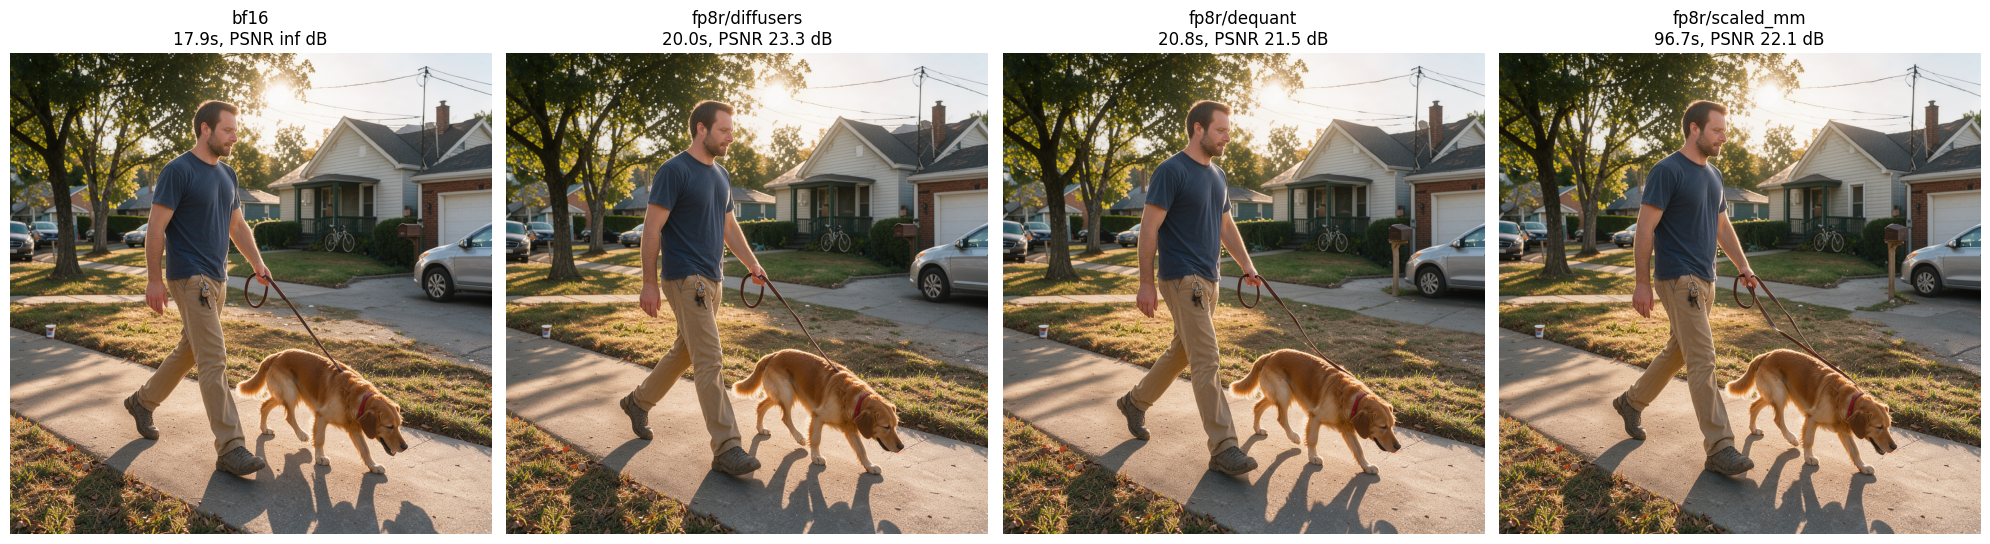

run                            torch  seconds  transformer GiB    PSNR
bf16_torch214                 2.14.1     18.0            10.34     nan
bf16_torch215                 2.15.0     17.9            10.34     nan
fp8r_diffusers_torch215       2.15.0     20.0             5.84    23.3
fp8r_dequant_torch215         2.15.0     20.8             5.84    21.5
fp8r_scaled_mm_torch215       2.15.0     96.7             5.84    22.1


In [6]:
import matplotlib.pyplot as plt

panels = {"bf16": bf16, **{f"fp8r/{k}": v for k, v in fp8_runs.items()}}
fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 5.4))
for ax, (name, run) in zip(axes, panels.items()):
    ax.imshow(run.image)
    ax.set_title(f"{name}\n{run.seconds:.1f}s, PSNR {psnr(bf16.image, run.image):.1f} dB")
    ax.axis("off")
plt.tight_layout()
plt.show()

results = json.loads(RESULTS.read_text())
print(f"{'run':<28}{'torch':>8}{'seconds':>9}{'transformer GiB':>17}{'PSNR':>8}")
for name, r in results.items():
    print(
        f"{name:<28}{r['torch']:>8}{r['seconds']:>9.1f}{r['transformer_gib']:>17.2f}{r.get('psnr_vs_bf16', float('nan')):>8.1f}"
    )